In [159]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [160]:
df = pd.read_csv('sales_data_sample.csv', encoding='latin1')
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [161]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


In [162]:
df.isnull().sum()

ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [163]:
df['DEALSIZE'].unique()

array(['Small', 'Medium', 'Large'], dtype=object)

In [164]:
df['TERRITORY'] = df['TERRITORY'].fillna('Unknown')

In [165]:
df['MSRP'].head()

0    95
1    95
2    95
3    95
4    95
Name: MSRP, dtype: int64

Text(0.5, 1.0, 'TERRITORY')

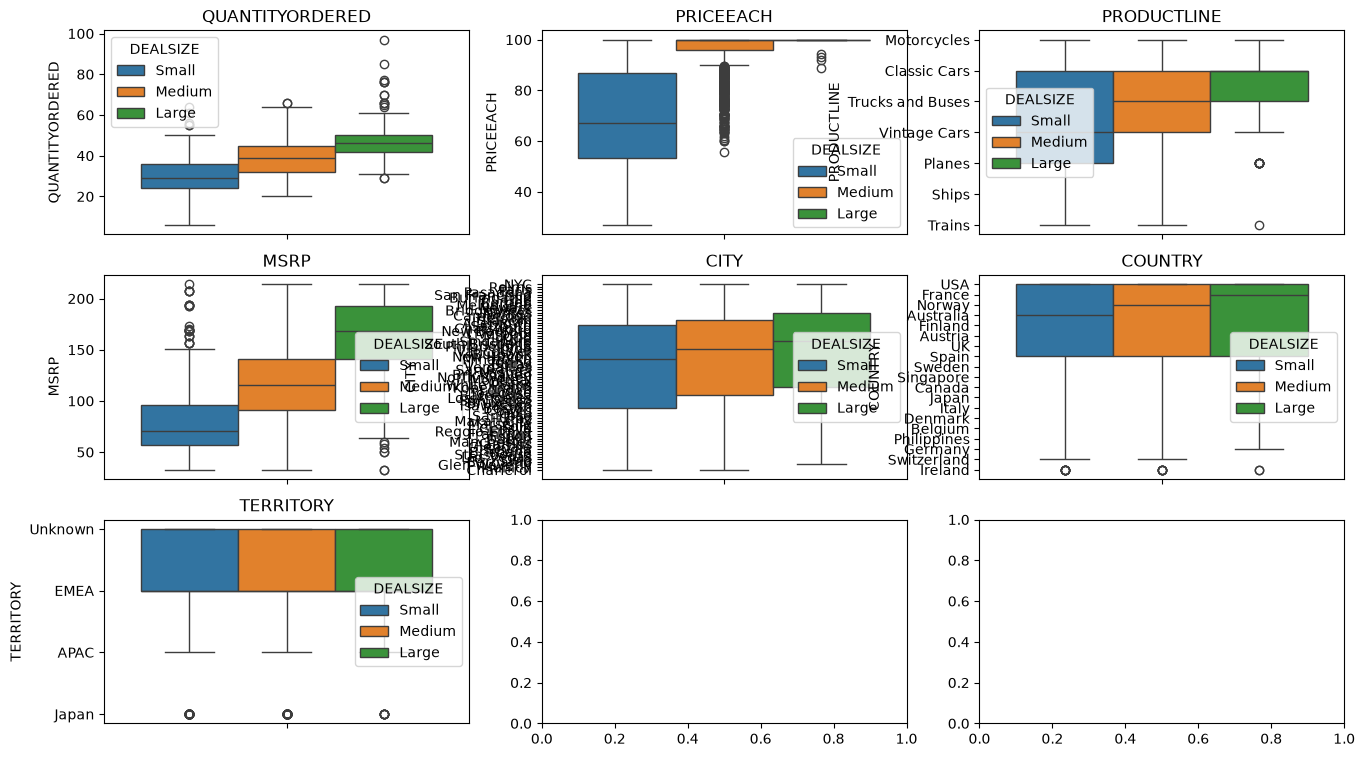

In [166]:
fig, axes = plt.subplots(3,3,figsize=(16,9))

sns.boxplot(df,y='QUANTITYORDERED',hue='DEALSIZE',ax=axes[0,0])
axes[0,0].set_title('QUANTITYORDERED')
sns.boxplot(df,y='PRICEEACH',hue='DEALSIZE',ax=axes[0,1])
axes[0,1].set_title('PRICEEACH')
sns.boxplot(df,y='PRODUCTLINE',hue='DEALSIZE',ax=axes[0,2])
axes[0,2].set_title('PRODUCTLINE')
sns.boxplot(df,y='MSRP',hue='DEALSIZE',ax=axes[1,0])
axes[1,0].set_title('MSRP')
sns.boxplot(df,y='CITY',hue='DEALSIZE',ax=axes[1,1])
axes[1,1].set_title('CITY')
sns.boxplot(df,y='COUNTRY',hue='DEALSIZE',ax=axes[1,2])
axes[1,2].set_title('COUNTRY')
sns.boxplot(df,y='TERRITORY',hue='DEALSIZE',ax=axes[2,0])
axes[2,0].set_title('TERRITORY')

In [168]:
X = df[['QUANTITYORDERED','PRICEEACH','MONTH_ID','YEAR_ID','PRODUCTLINE','MSRP','CITY','COUNTRY','TERRITORY']]
y=df['DEALSIZE']

X = pd.get_dummies(X,drop_first=True).astype(int)

In [169]:
X.isnull().sum()
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Columns: 104 entries, QUANTITYORDERED to TERRITORY_Unknown
dtypes: int64(104)
memory usage: 2.2 MB


In [170]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)

In [171]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [172]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled,y_train)

y_pred = knn.predict(X_test_scaled)
y_pred

array(['Medium', 'Small', 'Small', 'Medium', 'Small', 'Small', 'Medium',
       'Medium', 'Small', 'Medium', 'Small', 'Small', 'Large', 'Medium',
       'Medium', 'Medium', 'Medium', 'Large', 'Medium', 'Small', 'Medium',
       'Medium', 'Medium', 'Medium', 'Medium', 'Medium', 'Medium',
       'Small', 'Medium', 'Small', 'Medium', 'Medium', 'Small', 'Medium',
       'Small', 'Medium', 'Medium', 'Small', 'Medium', 'Medium', 'Medium',
       'Medium', 'Small', 'Medium', 'Small', 'Medium', 'Medium', 'Medium',
       'Small', 'Medium', 'Large', 'Medium', 'Small', 'Small', 'Medium',
       'Small', 'Medium', 'Small', 'Small', 'Medium', 'Medium', 'Large',
       'Small', 'Medium', 'Medium', 'Medium', 'Medium', 'Small', 'Small',
       'Medium', 'Small', 'Small', 'Medium', 'Medium', 'Small', 'Small',
       'Small', 'Medium', 'Small', 'Medium', 'Medium', 'Small', 'Small',
       'Small', 'Medium', 'Medium', 'Medium', 'Medium', 'Medium',
       'Medium', 'Medium', 'Small', 'Medium', 'Small', '

In [173]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

[[  4  30   1]
 [ 11 206  52]
 [  0 115 146]]
              precision    recall  f1-score   support

       Large       0.27      0.11      0.16        35
      Medium       0.59      0.77      0.66       269
       Small       0.73      0.56      0.63       261

    accuracy                           0.63       565
   macro avg       0.53      0.48      0.49       565
weighted avg       0.63      0.63      0.62       565



<Axes: >

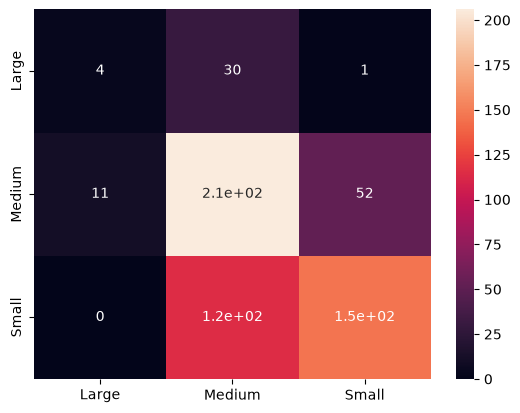

In [174]:
sns.heatmap(confusion_matrix(y_test, y_pred),
            annot=True,
            xticklabels=knn.classes_,
            yticklabels=knn.classes_)

In [175]:
print(y_test.value_counts(normalize=True) * 100)

DEALSIZE
Medium    47.610619
Small     46.194690
Large      6.194690
Name: proportion, dtype: float64
